<a href="https://colab.research.google.com/github/fxrdhan/Practical-Statistics-for-Data-Scientists/blob/main/Chapter_06_Statistical_Machine_Learning/Chapter_06_Statistical_Machine_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Chapter 6 — Statistical Machine Learning

| | |
|---|---|
| **Book** | *Practical Statistics for Data Scientists: 50+ Essential Concepts Using R and Python*, 2nd edition — Peter Bruce, Andrew Bruce and Peter Gedeck (O'Reilly Media, 2020) |
| **Code reproduced here** | the Python code of the book's official repository, `gedeck/practical-statistics-for-data-scientists` (GNU General Public License v3) |
| **Versions used to run this notebook** | printed by the setup cell |
| **What this notebook contains** | a summary of every section of the chapter, the theory behind it, the book's Python code reproduced and executed, and a short analysis of the outputs |

## Chapter overview

The methods of the previous chapters are built on a statistical model of the data (a distribution, a linear relationship). The methods of this chapter come from machine learning: they are **data-driven** and make fewer assumptions about the structure of the data, which makes them good for prediction and less suited to explaining it. The chapter presents four of them, in increasing order of power and complexity: **K-nearest neighbors** (classify a record like its most similar records), **tree models** (a set of if-then rules that split the data), the **random forest** (many trees fitted to resampled data and averaged, **bagging**) and **boosting** (a sequence of trees, each correcting the errors of the previous ones, with the package **XGBoost**). Along the way it introduces the tools that all of them share: standardization of predictors, measures of impurity, variable importance, regularization against overfitting, and the choice of hyperparameters by cross-validation.

### Sections of this chapter

| # | Section of the book | Python code in the book |
|---|---|---|
| 1 | K-nearest neighbors | a small example, standardization, KNN as a feature engine |
| 2 | Tree models | a decision tree for the loan data, the partition of the plane, impurity measures |
| 3 | Bagging and the random forest | a random forest, the out-of-bag score, variable importance |
| 4 | Boosting | XGBoost, regularization, hyperparameters and cross-validation |

### How to read this notebook

Every section has the same structure: a **Summary** (what the book says, condensed in my own words; the book itself is not quoted), the **Theory** behind the section, the **Book code** (the official Python code of the chapter, reproduced and executed) and a short **Output analysis**.

Every code cell starts with a label comment: `# BOOK CODE` for code of the official repository (the setup cells are labelled `# SETUP` and are not part of the book). The book's code is reproduced as it is; the cells that draw random numbers without a seed in the script start with a seeding line marked `# NOT IN THE BOOK`, so that every run gives the same output.

---
## 0. Setup

The datasets of the book live in the official repository, in its `data` folder. The helper `ensure_data` below looks for each file in a folder called `data` next to the notebook and **downloads it from the official repository the first time** it is missing (this is the only use of the network; the folder is not part of this repository, see `.gitignore`). The files of this chapter are `loan200.csv` (200 loans), `loan3000.csv` (3,000 loans) and `loan_data.csv.gz` (45,342 loans, half of them in default).

The setup cell also prints the versions of the libraries, because the code of the book was written for older ones. The package `dmba` (the book authors' helper for plotting trees) is not part of a standard Python installation; the cell installs it if it is missing (this is the case in Google Colab). To draw the tree of section 2, `dmba` also needs the program **Graphviz** (`dot`) on the computer: it is present in Google Colab, otherwise it can be installed with the package manager of the system (for example `apt install graphviz` or `brew install graphviz`).

In [1]:
# SETUP
import importlib.util
import platform
import subprocess
import sys
import urllib.request
import warnings
from pathlib import Path

# Google Colab does not ship `dmba` (the tree plot of section 2); install it when it is missing
if importlib.util.find_spec("dmba") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "dmba"])

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import seaborn as sns
import sklearn
import xgboost

print(f"Python       : {platform.python_version()}")
print(f"NumPy        : {np.__version__}")
print(f"pandas       : {pd.__version__}")
print(f"SciPy        : {scipy.__version__}")
print(f"scikit-learn : {sklearn.__version__}")
print(f"XGBoost      : {xgboost.__version__}")
print(f"seaborn      : {sns.__version__}")
print(f"Matplotlib   : {matplotlib.__version__}")

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

# print warnings without the file path, so that the saved output does not depend on the machine
warnings.formatwarning = lambda message, category, filename, lineno, line=None: f"{category.__name__}: {message}\n"

# --- the datasets of the official repository ---------------------------------------------------------
DATA = Path("data")
DATA_URL = "https://raw.githubusercontent.com/gedeck/practical-statistics-for-data-scientists/master/data/"


def ensure_data(*names):
    """Make sure that the files `names` exist in the folder `data`; download the missing ones."""
    DATA.mkdir(exist_ok=True)
    for name in names:
        if not (DATA / name).exists():
            urllib.request.urlretrieve(DATA_URL + name, DATA / name)
    return DATA


ensure_data("loan200.csv", "loan3000.csv", "loan_data.csv.gz")

# --- a quiet, colour-blind-safe style (global: it also applies to the figures of the book code) --------
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#8a63c7", "#d4a017"]  # blue, orange, aqua, violet, gold
INK, INK_SOFT, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.8, "grid.linestyle": "-",
    "axes.titlecolor": INK, "axes.titlesize": 11.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": INK_SOFT, "axes.labelsize": 10,
    "xtick.color": AXIS, "ytick.color": AXIS, "xtick.labelcolor": INK_SOFT, "ytick.labelcolor": INK_SOFT,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "lines.linewidth": 2, "legend.frameon": False, "legend.labelcolor": INK_SOFT,
    "figure.dpi": 110, "font.size": 10,
})

Python       : 3.12.3
NumPy        : 2.5.4
pandas       : 3.1.0
SciPy        : 1.16.3
scikit-learn : 1.9.1
XGBoost      : 3.4.1
seaborn      : 0.13.2
Matplotlib   : 3.11.2


The imports and the paths of the official script follow (the official script finds its data folder with a helper module; here `DATA` comes from the setup cell). The script ends its imports with an empty `print()`, which only separates the messages of the imported packages from the output of the code, and sets an environment variable that avoids a crash of XGBoost on some systems. Importing `dmba` has a side effect: when it finds no display (a server, or a notebook run in the background) it prints a message and switches Matplotlib to the non-interactive `Agg` backend, and then no figure appears in the notebook. The cell after the imports, which is not part of the book, switches the figures on again.

In [2]:
# BOOK CODE (imports and paths of the official script; `DATA` comes from the setup cell of this notebook)
import math
import os
import random
from pathlib import Path
from collections import defaultdict
from itertools import product


import pandas as pd
import numpy as np

from sklearn import preprocessing
from sklearn.neighbors import KNeighborsClassifier
from sklearn import metrics
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from xgboost import XGBClassifier

from dmba import plotDecisionTree, textDecisionTree

import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
print()

# Define paths to data sets. If you don't keep your data in the same directory as the code, adapt the path names.

LOAN200_CSV = DATA / 'loan200.csv'
LOAN3000_CSV = DATA / 'loan3000.csv'
LOAN_DATA_CSV = DATA / 'loan_data.csv.gz'

# Set this if the notebook crashes in the XGBoost part.

os.environ['KMP_DUPLICATE_LIB_OK'] = 'TRUE'

no display found. Using non-interactive Agg backend



In [3]:
# SETUP (continued; not in the book): show the figures in the notebook although `dmba` may have selected the Agg backend
%matplotlib inline

---
## 1. K-nearest neighbors

*Book section: "K-Nearest Neighbors" (a small example: predicting loan default, distance metrics, one hot encoder, standardization, choosing K, KNN as a feature engine). The code of the script classifies a loan from the loans that resemble it.*

### Summary

* The idea of **K-nearest neighbors (KNN)** is simple: to classify a new record, look for the $K$ records of the training data that are most **similar** to it (its neighbours, in terms of the predictors) and let them vote; the class with the most votes wins, and the share of the votes is a probability. For a numeric outcome the average of the neighbours is used. KNN fits no model: all the work is done at prediction time.
* **A small example.** A new loan is classified from the 20 loans of a data set of 200 that are closest to it in the payment-to-income ratio and the debt-to-income ratio (`dti`). Of these 20 neighbours, 9 are in default and 11 paid off, so the predicted probability of default is 0.45 and the loan is classified as paid off. The figure shows the new loan, the neighbours and the circle that contains them.
* **Distance metrics** measure how similar two records are. The usual one is the **Euclidean distance**, the square root of the sum of the squared differences of the predictors; the **Manhattan distance** adds the absolute differences (the distance in a grid of city blocks) and is less affected by a single large difference.
* **One hot encoder.** KNN needs numeric predictors; a categorical variable is converted to binary columns, one per level (one-hot encoding), as in the regression chapter.
* **Standardization (normalization, z-scores).** Variables measured on different scales do not contribute equally to a distance: the variable with the largest numbers dominates. The remedy is to subtract the mean and divide by the standard deviation of each variable before computing the distances. In the example, the five nearest neighbours of a loan found with the raw variables are practically all equal in the revolving balance (about 1,690 dollars), the variable with the largest scale, and differ a lot in the others; with the standardized variables the neighbours are close in the payment-to-income ratio, the debt-to-income ratio and the utilization, and the revolving balance, which no longer dominates, varies from 278 to 2,917 dollars.
* **Choosing K.** A small $K$ follows the training data very closely (low bias, high variance: it overfits, noise decides the prediction); a large $K$ smooths too much (it misses local structure). The best $K$ is chosen by trying a range of values on data that were not used for the fit (cross-validation); the code of the chapter uses $K = 20$ and $K = 5$ without searching for the best value.
* **KNN as a feature engine.** The predicted probability of a KNN model can be used as a **new feature** in another model. In the example, the probability of default from a KNN model with six predictors becomes the variable `borrower_score` that the later models of the book use.

### Theory

**The classifier.** For a new point $x$ let $N_K(x)$ be the set of the $K$ training points with the smallest distance to $x$. The estimated probability of class $c$ is
$$\hat p(c \mid x) = \frac{1}{K}\sum_{i \in N_K(x)} \mathbf 1\{y_i = c\},$$
and the predicted class is the one with the largest estimate. With $K = 1$ the training error is zero; the error on new data first falls and then rises as $K$ decreases.

**Distances.** The Euclidean distance is $d(x, x') = \sqrt{\sum_j (x_j - x'_j)^2}$ and the Manhattan distance $\sum_j |x_j - x'_j|$; both are special cases of the Minkowski distance $\bigl(\sum_j |x_j - x'_j|^q\bigr)^{1/q}$. Standardized variables have mean 0 and standard deviation 1: $z = (x - \bar x)/s$.

**The curse of dimensionality.** With many predictors the points are far from each other in all directions, and the nearest neighbour is hardly nearer than the average point: the notion of "neighbourhood" loses its meaning. KNN works best with a small number of informative predictors and enough data.

**Cost.** Every prediction compares the new record with all the training records, which is slow for large data; data structures such as k-d trees speed it up for few dimensions.

### Book code

The small example. The first loan of the data set of 200 is taken as the new loan and the other 199 as the training data; the model with $K = 20$ gives the predicted probabilities of the two classes (in the alphabetical order of the classes: default, paid off).

In [4]:
# BOOK CODE (A Small Example: Predicting Loan Default): the 20 nearest neighbours of a loan
loan200 = pd.read_csv(LOAN200_CSV)

predictors = ['payment_inc_ratio', 'dti']
outcome = 'outcome'


newloan = loan200.loc[0:0, predictors]
X = loan200.loc[1:, predictors]
y = loan200.loc[1:, outcome]

knn = KNeighborsClassifier(n_neighbors=20)
knn.fit(X, y)
knn.predict(newloan)
print(knn.predict_proba(newloan))

[[0.45 0.55]]


The figure of the book: the 200 loans, the new loan and its neighbours in solid colours, and the circle whose radius is the largest distance to one of the 20 neighbours (in data units it is a circle; it looks a little elongated because the two axes have different scales).

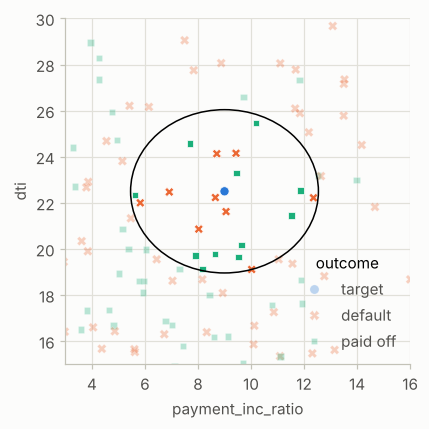

In [5]:
# BOOK CODE (A Small Example: Predicting Loan Default): the neighbours of the new loan
nbrs = knn.kneighbors(newloan)
maxDistance = np.max(nbrs[0][0])

fig, ax = plt.subplots(figsize=(4, 4))
sns.scatterplot(x='payment_inc_ratio', y='dti', style='outcome',
                hue='outcome', data=loan200, alpha=0.3, ax=ax)
sns.scatterplot(x='payment_inc_ratio', y='dti', style='outcome',
                hue='outcome',
                data=pd.concat([loan200.loc[0:0, :], loan200.loc[nbrs[1][0] + 1,:]]),
                ax=ax, legend=False)
ellipse = Ellipse(xy=newloan.values[0],
                  width=2 * maxDistance, height=2 * maxDistance,
                  edgecolor='black', fc='None', lw=1)
ax.add_patch(ellipse)
ax.set_xlim(3, 16)
ax.set_ylim(15, 30)

plt.tight_layout()
plt.show()

Standardization. The script reads the full loan data (45,342 loans) and looks, for the first loan, at the five nearest neighbours: first with the raw predictors, then with standardized ones (`StandardScaler`). The table of the first output is the new loan; the tables after it are its five neighbours.

In [6]:
# BOOK CODE (Standardization): the nearest neighbours without standardization
loan_data = pd.read_csv(LOAN_DATA_CSV)
loan_data = loan_data.drop(columns=['Unnamed: 0', 'status'])
loan_data['outcome'] = pd.Categorical(loan_data['outcome'],
                                      categories=['paid off', 'default'],
                                      ordered=True)


predictors = ['payment_inc_ratio', 'dti', 'revol_bal', 'revol_util']
outcome = 'outcome'

newloan = loan_data.loc[0:0, predictors]
print(newloan)
X = loan_data.loc[1:, predictors]
y = loan_data.loc[1:, outcome]

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X, y)

nbrs = knn.kneighbors(newloan)
print(X.iloc[nbrs[1][0], :])

   payment_inc_ratio  dti  revol_bal  revol_util
0             2.3932  1.0       1687         9.4
       payment_inc_ratio   dti  revol_bal  revol_util
35536            1.47212  1.46       1686        10.0
33651            3.38178  6.37       1688         8.4
25863            2.36303  1.39       1691         3.5
42953            1.28160  7.14       1684         3.9
43599            4.12244  8.98       1684         7.2


In [7]:
# BOOK CODE (Standardization): the nearest neighbours with standardized predictors
newloan = loan_data.loc[0:0, predictors]
X = loan_data.loc[1:, predictors]
y = loan_data.loc[1:, outcome]

scaler = preprocessing.StandardScaler()
scaler.fit(X * 1.0)

X_std = scaler.transform(X * 1.0)
newloan_std = scaler.transform(newloan * 1.0)

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_std, y)

nbrs = knn.kneighbors(newloan_std)
print(X.iloc[nbrs[1][0], :])

       payment_inc_ratio   dti  revol_bal  revol_util
2080             2.61091  1.03       1218         9.7
1438             2.34343  0.51        278         9.9
30215            2.71200  1.34       1075         8.5
28542            2.39760  0.74       2917         7.4
44737            2.34309  1.37        488         7.2


KNN as a feature engine. A KNN model with six predictors and $K = 20$ is fitted to all the loans, and its predicted probability (the first column of `predict_proba`) becomes the new variable `borrower_score`. The scatterplot of the scores (with a little random jitter in the vertical direction, so that the points do not coincide) shows that the probabilities take only a few values (multiples of 1/20), and `describe` summarizes them. The script has no seed for the jitter; the cell starts with one, marked `NOT IN THE BOOK`.

count    45342.000000
mean         0.501098
std          0.128736
min          0.000000
25%          0.400000
50%          0.500000
75%          0.600000
max          0.950000
Name: borrower_score, dtype: float64


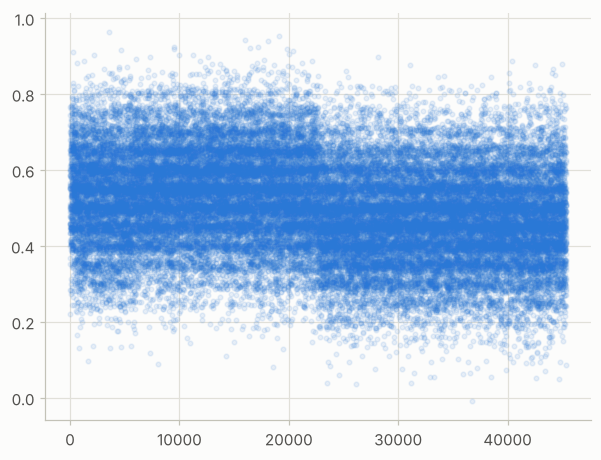

In [8]:
# BOOK CODE (KNN as a Feature Engine): the borrower score from a KNN model
random.seed(1)  # NOT IN THE BOOK: the jitter of the scatterplot is random and the script has no seed

loan_data = pd.read_csv(LOAN_DATA_CSV)
loan_data = loan_data.drop(columns=['Unnamed: 0', 'status'])
loan_data['outcome'] = pd.Categorical(loan_data['outcome'],
                                      categories=['paid off', 'default'],
                                      ordered=True)

predictors = ['dti', 'revol_bal', 'revol_util', 'open_acc',
              'delinq_2yrs_zero', 'pub_rec_zero']
outcome = 'outcome'

X = loan_data[predictors]
y = loan_data[outcome]

knn = KNeighborsClassifier(n_neighbors=20)
knn.fit(X, y)
plt.scatter(range(len(X)), [bs + random.gauss(0, 0.015) for bs in knn.predict_proba(X)[:,0]],
            alpha=0.1, marker='.')
knn.predict_proba(X)[:, 0]

loan_data['borrower_score'] = knn.predict_proba(X)[:, 0]
print(loan_data['borrower_score'].describe())

**Output analysis.**

* **The small example.** `predict_proba` gives `[[0.45 0.55]]`, in the order of the classes (default, paid off): 9 of the 20 nearest neighbours are in default and 11 paid off, so the probability of default is 0.45 and the new loan is classified as paid off, narrowly. In the figure the loans with solid markers are the new loan and its 20 neighbours, and the circle has the distance to the farthest neighbour as its radius.
* **Standardization.** The new loan has a payment-to-income ratio of 2.39, a debt-to-income ratio of 1.0, a revolving balance of 1,687 dollars and a utilization of 9.4%. With the raw variables its five nearest neighbours have balances of 1,684 to 1,691, within 3 dollars of the new loan, while their debt-to-income ratios are 1.39 to 8.98 and their payment ratios 1.28 to 4.12: the balance is in the thousands, the other variables are in single digits, and the balance alone decides the distance. With standardized variables the neighbours are close in the other variables (payment ratio 2.34 to 2.71, debt-to-income ratio 0.51 to 1.37, utilization 7.2 to 9.9) and the balance now varies from 278 to 2,917 dollars, because the balance has a large standard deviation, so a difference of a thousand dollars is now a small distance.
* **The feature engine.** The new variable `borrower_score` (the first column of `predict_proba`, which is the probability of the first class, *default*; see the notes at the end) has 45,342 values with a mean of 0.501, a standard deviation of 0.129, a minimum of 0, a maximum of 0.95 and quartiles of 0.40, 0.50 and 0.60. With $K = 20$ it can take only the values 0, 0.05, ..., 1, which is why the scatterplot shows horizontal bands. The data file lists the 22,671 loans in default first and then the 22,671 paid off, and the left half of the plot is indeed a little higher (a higher probability of default), but the two halves overlap almost completely: the average of the score is 0.537 for the loans in default and 0.465 for the loans paid off, so six predictors and a KNN model separate the two groups only weakly.

---
## 2. Tree models

*Book section: "Tree Models" (a simple example, the recursive partitioning algorithm, measuring homogeneity or impurity, stopping the tree from growing, predicting a continuous value, how trees are used). The code of the script fits a tree to the loans and draws it, its partition of the plane and the measures of impurity.*

### Summary

* A **tree model**, also called a **decision tree** or CART (classification and regression tree), is a set of **if-then rules** that is easy to read and to explain: it asks a series of questions about the predictors ("is the borrower score below 0.575?") and ends in a **leaf** with a predicted class or value. It was among the earliest methods of data science for finding structure, including interactions and nonlinear effects, without a model, and trees are the building blocks of the random forest and boosting.
* **The example:** a tree with two predictors, the borrower score and the payment-to-income ratio, fitted to 3,000 loans, has six leaves. Its first question is whether the borrower score is at most 0.575; the left branch asks next whether it is at most 0.325 (then the predicted probability of default is 0.785), and so on. The same rules are printed as text by `textDecisionTree`.
* **The recursive partitioning algorithm** divides the predictor space into rectangles. It looks for the predictor and the split value that give the **most homogeneous** (purest) two parts in terms of the outcome, splits the data there, and repeats the search in each part, until no split improves the purity enough or the parts are too small. The figure shows the resulting division of the (borrower score, payment-to-income ratio) plane.
* **Measuring homogeneity or impurity.** A part is pure when it contains records of one class only. The usual measures are the **Gini impurity** and the **entropy**; both are zero for a pure part and largest when the classes are mixed 50:50 (the share of misclassified records is a cruder alternative). The tree chooses the split that lowers the weighted impurity the most.
* **Stopping the tree from growing.** A tree grown until all leaves are pure fits the training data perfectly and generalizes poorly (overfitting). The tree is therefore stopped, by limiting the depth or the minimum number of records in a leaf, or by requiring a minimum decrease of impurity for a split (`min_impurity_decrease=0.003` in the example), or it is grown fully and then **pruned** back, using cross-validation to decide how far.
* **Predicting a continuous value.** The same method works for a numeric outcome (a **regression tree**): the prediction of a leaf is the mean of the outcome of its records, and the splits are chosen to reduce the variance within the parts.
* **How trees are used.** A single tree is a good tool for exploring the data and for rules that can be explained to others; for predictive accuracy it is usually beaten by ensembles of trees (the next sections).

### Theory

**Impurity.** For a node with class shares $p_1, \dots, p_K$, the **Gini impurity** is $G = \sum_k p_k(1 - p_k) = 1 - \sum_k p_k^2$ (for two classes $2p(1-p)$; the script plots $p(1-p)$ scaled to 1 at $p = 0.5$), and the **entropy** is $H = -\sum_k p_k\log_2 p_k$. The misclassification rate of the node is $1 - \max_k p_k$.

**The split criterion.** A split sends $n_L$ of the $n$ records of the node to the left and $n_R$ to the right. It is chosen to maximize the decrease of impurity
$$\Delta = I(\text{node}) - \frac{n_L}{n}I(\text{left}) - \frac{n_R}{n}I(\text{right}).$$
A split on a numeric predictor has the form "$x_j \le s$"; the best $s$ is searched among the midpoints between the sorted values of $x_j$. The parameter `min_impurity_decrease` of scikit-learn is the smallest weighted decrease that is accepted.

**Pruning.** The cost-complexity criterion $R_\alpha(T) = R(T) + \alpha\,|T|$ (the error of the tree plus a penalty for the number of leaves $|T|$) defines a sequence of smaller trees; $\alpha$ is chosen by cross-validation.

**Instability.** A small change of the data can change the first split and with it the whole tree: a tree has a high variance. Averaging many trees (bagging) reduces it.

### Book code

A decision tree with the borrower score and the payment-to-income ratio (entropy as the impurity measure, a minimum impurity decrease of 0.003). The function `plotDecisionTree` of `dmba` draws it with Graphviz.

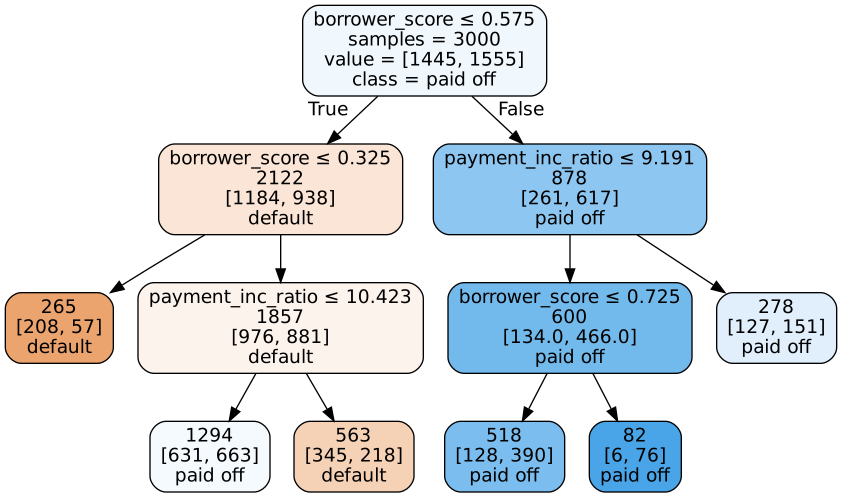

In [9]:
# BOOK CODE (A Simple Example): the decision tree
# The package _scikit-learn_ has the class `DecisionTreeClassifier` to build a decision tree model. The function `plotDecisionTree` from the _dmba_ package can be used to visualize the tree.

loan3000 = pd.read_csv(LOAN3000_CSV)

predictors = ['borrower_score', 'payment_inc_ratio']
outcome = 'outcome'

X = loan3000[predictors]
y = loan3000[outcome]

loan_tree = DecisionTreeClassifier(random_state=1, criterion='entropy',
                                   min_impurity_decrease=0.003)
loan_tree.fit(X, y)
plotDecisionTree(loan_tree, feature_names=predictors, class_names=loan_tree.classes_)

The same tree as text: for every node the feature (0 is the borrower score, 1 the payment-to-income ratio) and the threshold, and for every leaf the probabilities of the classes in the order of `loan_tree.classes_` (default, paid off).

In [10]:
# BOOK CODE (A Simple Example): the tree as text
print(textDecisionTree(loan_tree))

node=0 test node: go to node 1 if 0 <= 0.5750000178813934 else to node 6
  node=1 test node: go to node 2 if 0 <= 0.32500000298023224 else to node 3
    node=2 leaf node: [[np.float64(0.785), np.float64(0.215)]]
    node=3 test node: go to node 4 if 1 <= 10.42264986038208 else to node 5
      node=4 leaf node: [[np.float64(0.488), np.float64(0.512)]]
      node=5 leaf node: [[np.float64(0.613), np.float64(0.387)]]
  node=6 test node: go to node 7 if 1 <= 9.19082498550415 else to node 10
    node=7 test node: go to node 8 if 0 <= 0.7249999940395355 else to node 9
      node=8 leaf node: [[np.float64(0.247), np.float64(0.753)]]
      node=9 leaf node: [[np.float64(0.073), np.float64(0.927)]]
    node=10 leaf node: [[np.float64(0.457), np.float64(0.543)]]


The partition: the loans of the two classes in the plane of the two predictors, with the splits of the tree drawn as lines and each region labelled with its predicted class (the numbers of the splits are taken from the text of the tree).

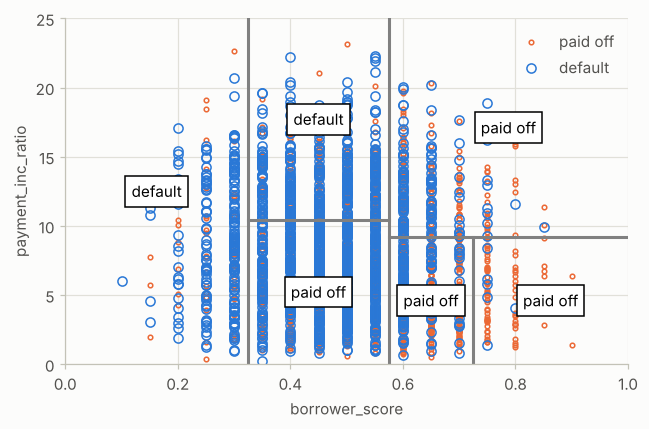

In [11]:
# BOOK CODE (The Recursive Partitioning Algorithm): the partition of the plane
fig, ax = plt.subplots(figsize=(6, 4))

loan3000.loc[loan3000.outcome=='paid off'].plot(
    x='borrower_score', y='payment_inc_ratio', style='.',
    markerfacecolor='none', markeredgecolor='C1', ax=ax)
loan3000.loc[loan3000.outcome=='default'].plot(
    x='borrower_score', y='payment_inc_ratio', style='o',
    markerfacecolor='none', markeredgecolor='C0', ax=ax)
ax.legend(['paid off', 'default']);
ax.set_xlim(0, 1)
ax.set_ylim(0, 25)
ax.set_xlabel('borrower_score')
ax.set_ylabel('payment_inc_ratio')

x0 = 0.575
x1a = 0.325; y1b = 9.191
y2a = 10.423; x2b = 0.725
ax.plot((x0, x0), (0, 25), color='grey')
ax.plot((x1a, x1a), (0, 25), color='grey')
ax.plot((x0, 1), (y1b, y1b), color='grey')
ax.plot((x1a, x0), (y2a, y2a), color='grey')
ax.plot((x2b, x2b), (0, y1b), color='grey')

labels = [('default', (x1a / 2, 25 / 2)),
          ('default', ((x0 + x1a) / 2, (25 + y2a) / 2)),
          ('paid off', ((x0 + x1a) / 2, y2a / 2)),
          ('paid off', ((1 + x0) / 2, (y1b + 25) / 2)),
          ('paid off', ((1 + x2b) / 2, (y1b + 0) / 2)),
          ('paid off', ((x0 + x2b) / 2, (y1b + 0) / 2)),
         ]
for label, (x, y) in labels:
    ax.text(x, y, label, bbox={'facecolor':'white'},
            verticalalignment='center', horizontalalignment='center')

plt.tight_layout()
plt.show()

The measures of impurity as a function of the share $x$ of the minority class (from 0 to 0.5): the misclassification rate ("Accuracy" in the legend of the script, $2x$), the Gini impurity scaled to 1 at $x = 0.5$, and the entropy.

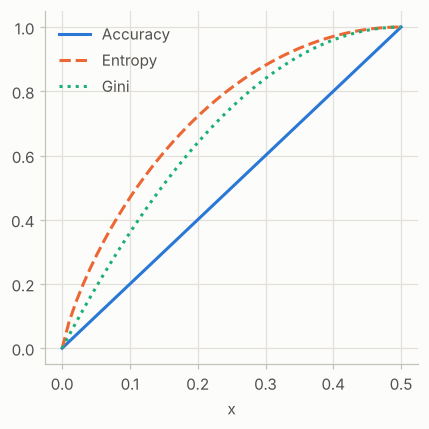

In [12]:
# BOOK CODE (Measuring Homogeneity or Impurity): Gini impurity and entropy
def entropyFunction(x):
    if x == 0: return 0
    return -x * math.log(x, 2) - (1 - x) * math.log(1 - x, 2)

def giniFunction(x):
    return x * (1 - x)

x = np.linspace(0, 0.5, 50)
impure = pd.DataFrame({
    'x': x,
    'Accuracy': 2 * x,
    'Gini': [giniFunction(xi) / giniFunction(.5) for xi in x],
    'Entropy': [entropyFunction(xi) for xi in x],
})

fig, ax = plt.subplots(figsize=(4, 4))

impure.plot(x='x', y='Accuracy', ax=ax, linestyle='solid')
impure.plot(x='x', y='Entropy', ax=ax, linestyle='--')
impure.plot(x='x', y='Gini', ax=ax, linestyle=':')

plt.tight_layout()
plt.show()

**Output analysis.**

* **The tree.** It has 5 split nodes and 6 leaves. The root splits the 3,000 loans (1,445 in default, 1,555 paid off) at a borrower score of 0.575 into 2,122 loans on the left (1,184 in default) and 878 on the right (261 in default). The leaves, with the loans in default and paid off and the predicted class, are in the table.

| rule | loans | default / paid off | predicted |
|---|---|---|---|
| score $\le$ 0.325 | 265 | 208 / 57 (78.5% default) | default |
| 0.325 < score $\le$ 0.575 and ratio $\le$ 10.42 | 1,294 | 631 / 663 (48.8% default) | paid off |
| 0.325 < score $\le$ 0.575 and ratio > 10.42 | 563 | 345 / 218 (61.3% default) | default |
| 0.575 < score $\le$ 0.725 and ratio $\le$ 9.19 | 518 | 128 / 390 (24.7% default) | paid off |
| score > 0.725 and ratio $\le$ 9.19 | 82 | 6 / 76 (7.3% default) | paid off |
| score > 0.575 and ratio > 9.19 | 278 | 127 / 151 (45.7% default) | paid off |

* **Reading the tree.** The rules classify 1,833 of the 3,000 training loans correctly (61.1%), and two of the leaves (1,294 and 278 loans) are close to 50:50. The text version of the tree has the same splits (feature 0 is the borrower score, feature 1 the payment-to-income ratio, and the leaves give the probabilities of default and paid off); with `numpy` 2 the probabilities are printed as `np.float64(...)`.
* **The partition.** The borrower score takes values in steps of 0.05, so the loans lie on vertical stripes. The grey lines are the five splits: the two vertical lines at 0.325 and 0.575 and the vertical line at 0.725 below the ratio of 9.19, and the horizontal lines at 10.42 (between the two first vertical lines) and 9.19 (to the right of 0.575). The six regions are labelled with the predicted class: default on the left and in the upper middle, paid off in the other four.
* **The impurity measures.** All three are 0 for a pure node (x = 0) and 1 at 50:50 (x = 0.5). The misclassification rate is a straight line ($2x$), while the Gini impurity and the entropy are curves that rise faster at first, so that they are more sensitive to a small share of the minority class: at $x = 0.25$ the rate is 0.5, the scaled Gini impurity 0.75 and the entropy 0.81. The entropy is above the Gini impurity everywhere between 0 and 0.5, but they have similar shapes.

---
## 3. Bagging and the random forest

*Book section: "Bagging and the Random Forest" (bagging, random forest, variable importance, hyperparameters). The code of the script fits a random forest to the loans, follows its out-of-bag accuracy and compares three measures of variable importance.*

### Summary

* **Bagging** ("bootstrap aggregating") builds an **ensemble** of models: many **bootstrap samples** (samples with replacement of the same size as the data) are drawn, one model is fitted to each, and the predictions are combined, by majority vote for a class or by the average for a number. Averaging many different models reduces the variance of the prediction, and it helps most for unstable models such as trees.
* The **random forest** is bagging applied to trees with one more source of randomness: at every split the tree may only choose among a **random subset of the predictors** (in scikit-learn the argument `max_features`; the default for a classifier is the square root of the number of predictors). This keeps the trees from all starting with the same strong predictor, makes them less alike, and the average of less alike trees has a lower variance. A forest is much more accurate than a single tree, needs little tuning, and gives up the readable rules of a single tree.
* **The example.** A forest of 500 trees is fitted to the 3,000 loans with two predictors (the borrower score and the payment-to-income ratio). With `oob_score=True` it also keeps the **out-of-bag** predictions.
* **Out-of-bag (OOB) estimate.** A bootstrap sample leaves out about a third of the records. For each record, only the trees that did *not* see it vote, and the share of correct votes over all records is an honest estimate of the accuracy on new data, with no separate validation set. `oob_decision_function_` has these votes as probabilities (one row per loan, columns in the order of `rf.classes_`: default, paid off). The loop of the script repeats the fit with 20, 25, ..., 505 trees (limited to trees of depth 5) and plots the OOB accuracy against the number of trees: a larger forest does not overfit, it only costs more time, and the accuracy settles down as the number of trees grows (see the output analysis for this example).
* **Variable importance.** A forest does not give a coefficient per predictor, but it can say which predictors matter. The **impurity-based importance** (the Gini decrease, or the entropy decrease when the forest uses entropy) adds up, over all trees, the decrease of impurity of the splits that use the predictor. The **permutation importance** (the accuracy decrease) shuffles the values of one predictor in the validation data and measures how much the accuracy falls: if the predictor matters, shuffling it hurts. scikit-learn computes the first kind itself; the script computes the second by hand over three random splits of the data. The predictors are the 17 columns of the table of the loan data; the categorical ones are expanded to indicator columns, 33 columns in total.
* **Hyperparameters.** The main ones are the number of trees, the number of predictors tried at each split, and the minimum size of a leaf or the maximum depth of the trees. A forest is not very sensitive to them, but they can be tuned by cross-validation, as in section 4 for boosting.

### Theory

**Bootstrap.** A record is left out of a bootstrap sample of size $n$ with probability $(1 - 1/n)^n \to e^{-1} \approx 0.368$. Each tree therefore sees about 63.2% of the distinct records and the remaining 36.8% are its out-of-bag records.

**Why averaging helps.** If $B$ trees have predictions with variance $\sigma^2$ and a pairwise correlation $\rho$, their average has the variance
$$\operatorname{Var}\Bigl(\frac1B\sum_{b=1}^B \hat f_b(x)\Bigr) = \rho\,\sigma^2 + \frac{1-\rho}{B}\,\sigma^2 .$$
The second term disappears as $B$ grows (this is why adding trees does not overfit), but the first does not: only lower correlation between the trees can reduce it. The random choice of predictors at each split is exactly a way of reducing $\rho$.

**The out-of-bag estimate.** Let $\mathcal B_i$ be the set of the trees whose bootstrap sample does not contain record $i$. The out-of-bag prediction $\hat y_i^{\text{OOB}}$ is the vote of the trees in $\mathcal B_i$ and the out-of-bag error is $\frac1n\sum_i \mathbf 1\{\hat y_i^{\text{OOB}} \ne y_i\}$.

**Impurity importance.** For predictor $j$, $I_j = \frac1B\sum_b \sum_{t \in \text{splits of tree } b \text{ on } j} \frac{n_t}{n}\,\Delta_t$, where $\Delta_t$ is the decrease of impurity at node $t$ and $n_t$ its number of records; scikit-learn scales the $I_j$ to sum to 1. It is computed on the training data and tends to favour predictors with many possible split points (numeric and many-level variables).

**Permutation importance.** With $\text{acc}$ the accuracy on validation data and $\text{acc}_j$ the accuracy after shuffling column $j$, the script uses the relative decrease $(\text{acc} - \text{acc}_j)/\text{acc}$, averaged over the three splits. It can be slightly negative (shuffling a useless predictor can by chance improve the accuracy a little) and it is shared out among correlated predictors.

### Book code

The forest of 500 trees with the out-of-bag estimate. Each row of `oob_decision_function_` has the out-of-bag probabilities of one loan for the classes default and paid off.

In [13]:
# BOOK CODE (Random Forest): a forest of 500 trees and its out-of-bag probabilities
predictors = ['borrower_score', 'payment_inc_ratio']
outcome = 'outcome'

X = loan3000[predictors]
y = loan3000[outcome]

rf = RandomForestClassifier(n_estimators=500, random_state=1,
                            oob_score=True)
rf.fit(X, y)
print(rf.oob_decision_function_)

[[0.18131868 0.81868132]
 [0.26704545 0.73295455]
 [0.93333333 0.06666667]
 ...
 [1.         0.        ]
 [0.73157895 0.26842105]
 [0.68085106 0.31914894]]


The out-of-bag accuracy for forests of 20 to 505 trees (limited to a depth of 5, with entropy as the impurity measure). This is the slowest cell of the section: it fits 98 forests.

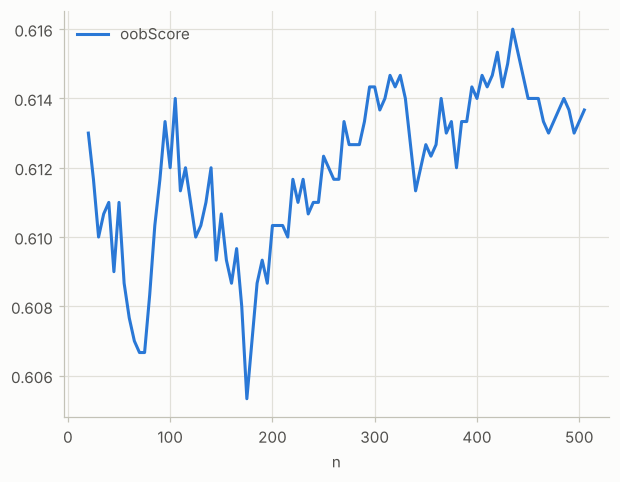

In [14]:
# BOOK CODE (Random Forest): the out-of-bag accuracy against the number of trees
n_estimator = list(range(20, 510, 5))
oobScores = []
for n in n_estimator:
    rf = RandomForestClassifier(n_estimators=n,
                                criterion='entropy', max_depth=5,
                                random_state=1, oob_score=True)
    rf.fit(X, y)
    oobScores.append(rf.oob_score_)

pd.DataFrame({
    'n': n_estimator,
    'oobScore': oobScores
}).plot(x='n', y='oobScore')
plt.show()

The predictions of the last forest of the loop (505 trees) for the loans of the training data, and the figure of the predicted classes in the plane of the two predictors.

In [15]:
# BOOK CODE (Random Forest): the predictions of the forest
predictions = X.copy()
predictions['prediction'] = rf.predict(X)
predictions.head()

,borrower_score,payment_inc_ratio,prediction
0,0.40,5.11135,default
1,0.40,5.43165,default
2,0.70,9.23003,paid off
3,0.40,2.33482,paid off
4,0.45,12.10320,default


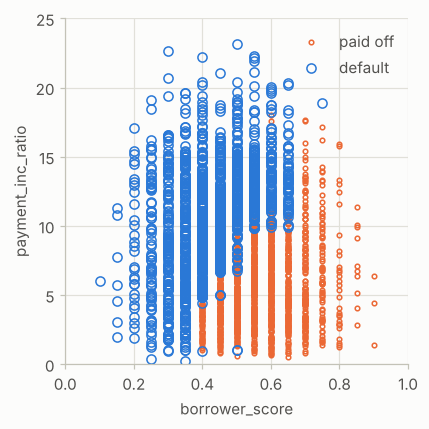

In [16]:
# BOOK CODE (Random Forest): the predicted classes in the plane of the predictors
fig, ax = plt.subplots(figsize=(4, 4))

predictions.loc[predictions.prediction=='paid off'].plot(
    x='borrower_score', y='payment_inc_ratio', style='.',
    markerfacecolor='none', markeredgecolor='C1', ax=ax)
predictions.loc[predictions.prediction=='default'].plot(
    x='borrower_score', y='payment_inc_ratio', style='o',
    markerfacecolor='none', markeredgecolor='C0', ax=ax)
ax.legend(['paid off', 'default']);
ax.set_xlim(0, 1)
ax.set_ylim(0, 25)
ax.set_xlabel('borrower_score')
ax.set_ylabel('payment_inc_ratio')

plt.tight_layout()
plt.show()

Variable importance. First the two forests on all the loans and all 33 columns: one with the Gini impurity (the default) and one with entropy; their `feature_importances_` are the "Gini decrease" and the "entropy decrease". The categorical predictors are expanded to indicator columns with `pd.get_dummies`. Note that `borrower_score` is the column computed by the KNN model of section 1 (the loan data are the ones loaded in the KNN cell).

In [17]:
# BOOK CODE (Variable importance): the forests with the Gini impurity and with entropy
# This is different to R. The accuracy decrease is not available out of the box.

predictors = ['loan_amnt', 'term', 'annual_inc', 'dti',
              'payment_inc_ratio', 'revol_bal', 'revol_util',
              'purpose', 'delinq_2yrs_zero', 'pub_rec_zero',
              'open_acc', 'grade', 'emp_length', 'purpose_',
              'home_', 'emp_len_', 'borrower_score']
outcome = 'outcome'

X = pd.get_dummies(loan_data[predictors], drop_first=True, dtype=int)
y = loan_data[outcome]

rf_all = RandomForestClassifier(n_estimators=500, random_state=1)
rf_all.fit(X, y)

rf_all_entropy = RandomForestClassifier(n_estimators=500, random_state=1,
                                        criterion='entropy')
print(rf_all_entropy.fit(X, y))

RandomForestClassifier(criterion='entropy', n_estimators=500, random_state=1)


The accuracy decrease: a forest is fitted to a random 70% of the loans, and for each column the values in the other 30% are shuffled and the accuracy is measured again; three random splits are averaged. The splits and the shuffling are random and the script has no seed: the cell starts with one, marked `NOT IN THE BOOK`. The cell prints the 33 columns sorted by their score.

In [18]:
# BOOK CODE (Variable importance): the accuracy decrease by permutation
np.random.seed(1)  # NOT IN THE BOOK: the forest, the splits and the permutations are random and the script has no seed

rf = RandomForestClassifier(n_estimators=500)
scores = defaultdict(list)

# crossvalidate the scores on a number of different random splits of the data
for _ in range(3):
    train_X, valid_X, train_y, valid_y = train_test_split(X, y,
                                                          test_size=0.3)
    rf.fit(train_X, train_y)
    acc = metrics.accuracy_score(valid_y, rf.predict(valid_X))
    for column in X.columns:
        X_t = valid_X.copy()
        X_t[column] = np.random.permutation(X_t[column].values)
        shuff_acc = metrics.accuracy_score(valid_y, rf.predict(X_t))
        scores[column].append((acc-shuff_acc)/acc)
print('Features sorted by their score:')
print(sorted([(round(np.mean(score), 4), feat) for
              feat, score in scores.items()], reverse=True))

Features sorted by their score:
[(np.float64(0.0762), 'borrower_score'), (np.float64(0.0416), 'grade'), (np.float64(0.0307), 'term_60 months'), (np.float64(0.0183), 'annual_inc'), (np.float64(0.0113), 'payment_inc_ratio'), (np.float64(0.0054), 'open_acc'), (np.float64(0.0046), 'dti'), (np.float64(0.0037), 'revol_util'), (np.float64(0.0035), 'purpose__small_business'), (np.float64(0.0027), 'home__RENT'), (np.float64(0.0026), 'purpose_credit_card'), (np.float64(0.0026), 'emp_length'), (np.float64(0.0023), 'purpose_small_business'), (np.float64(0.0015), 'purpose__debt_consolidation'), (np.float64(0.0014), 'loan_amnt'), (np.float64(0.0012), 'revol_bal'), (np.float64(0.0011), 'emp_len__ > 1 Year'), (np.float64(0.0011), 'delinq_2yrs_zero'), (np.float64(0.0009), 'home__OWN'), (np.float64(0.0007), 'purpose__other'), (np.float64(0.0004), 'pub_rec_zero'), (np.float64(0.0003), 'purpose_medical'), (np.float64(0.0002), 'purpose_other'), (np.float64(0.0001), 'purpose_vacation'), (np.float64(0.0001),

The figure of the book: the accuracy decrease and the Gini decrease for every column.

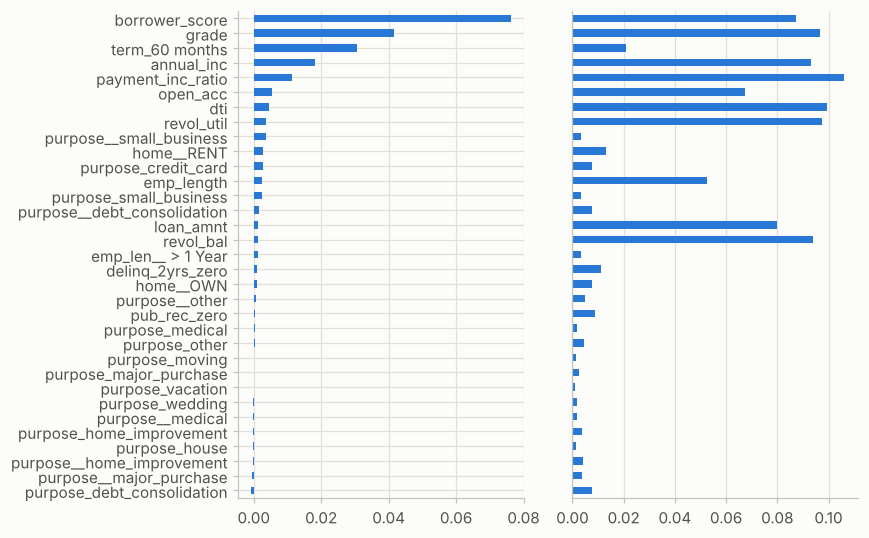

In [19]:
# BOOK CODE (Variable importance): the importances of the columns
importances = rf_all.feature_importances_

df = pd.DataFrame({
    'feature': X.columns,
    'Accuracy decrease': [np.mean(scores[column]) for column in
                         X.columns],
    'Gini decrease': rf_all.feature_importances_,
    'Entropy decrease': rf_all_entropy.feature_importances_,
})
df = df.sort_values('Accuracy decrease')

fig, axes = plt.subplots(ncols=2, figsize=(8, 5))
ax = df.plot(kind='barh', x='feature', y='Accuracy decrease',
             legend=False, ax=axes[0])
ax.set_ylabel('')

ax = df.plot(kind='barh', x='feature', y='Gini decrease',
             legend=False, ax=axes[1])
ax.set_ylabel('')
ax.get_yaxis().set_visible(False)

plt.tight_layout()
plt.show()

**Output analysis.**

* **The out-of-bag probabilities.** For the first loan the trees that did not see it vote 18.1% default and 81.9% paid off; for the second 26.7% and 73.3%; for the third 93.3% default. Among the last rows are a loan with 100% default votes (`[1. 0.]`) and two with 73.2% and 68.1% default. Each row sums to 1 and every loan has its own out-of-bag estimate.
* **The OOB accuracy against the number of trees** (forests of depth at most 5) stays between about 0.606 and 0.616 for every size: it is noisy, a little lower (about 0.607 to 0.611) for forests of 50 to 200 trees and a little higher (about 0.613 to 0.616) for those of more than 300 trees, and it does not improve further. The curve is flat on the scale of the accuracy itself, and the exact position of the highest point (about 430 trees) has no meaning. The honest accuracy of this two-predictor forest is about 61%, close to the 61.1% training accuracy of the single tree of section 2, so on these two predictors the forest is not more accurate than that tree was on its own training data.
* **The predictions** of the last forest of the loop (505 trees, depth 5) for the training loans are default, default, paid off, paid off, default for the first five. These are predictions for the data on which it was fitted. In the figure the loans are predicted to pay off when the borrower score is high and the payment-to-income ratio low; the boundary between the two classes is a staircase, because the forest is an average of trees made of rectangles.
* **The accuracy decrease** (permutation importance, printed sorted) is largest for the borrower score (0.0762: shuffling it makes the accuracy 7.6% lower, in relative terms), then the grade (0.0416), the term of 60 months (0.0307), the annual income (0.0183), the payment-to-income ratio (0.0113), the number of open accounts (0.0054) and the debt-to-income ratio (0.0046). All the other columns are below 0.004 and the last ten are within 0.0007 of zero (some are slightly negative: shuffling a useless column can by chance improve the accuracy a little). The data have both `purpose` and a regrouped `purpose_`, so the purposes appear twice, with names such as `purpose__small_business` and `purpose_small_business`.
* **The Gini decrease** (right panel) tells another story: it is largest for the payment-to-income ratio (0.106), the debt-to-income ratio (0.099), the utilization (0.097), the grade (0.097), the revolving balance (0.094), the annual income (0.093), the borrower score (0.087), the loan amount (0.080), the open accounts (0.067) and the length of employment (0.053), while the term of 60 months has only 0.021. So the balance, the utilization, the loan amount and the length of employment have a large Gini importance but an accuracy decrease of at most 0.004: the impurity measure is computed on the training data and favours numeric variables with many values, which the trees can split in many ways, while the permutation measure is computed on validation data. In my reading the accuracy decrease is the better guide here. One caution: the borrower score is itself a KNN estimate made from the outcomes of the loans (each loan is among its own 20 neighbours), so part of its importance may come from that.

---
## 4. Boosting

*Book section: "Boosting" (the boosting algorithm, XGBoost, regularization: avoiding overfitting, hyperparameters and cross-validation). The code of the script fits XGBoost models to the loans, penalizes them, and chooses the learning rate and the depth by cross-validation.*

### Summary

* **Boosting** is an ensemble method that builds a **sequence** of models. Each new model concentrates on what the models before it got wrong, and the final prediction is a weighted sum of all of them. In bagging the trees are independent of each other (and can be fitted in parallel); in boosting each tree depends on the previous ones.
* **Variants.** *AdaBoost* raises the weights of the misclassified records after each round. *Gradient boosting* fits each new tree to the errors of the current ensemble, seen as a step of gradient descent on a loss function. *Stochastic gradient boosting* adds the resampling of the bagging: each tree is fitted to a random sample of the records (and possibly of the columns), which makes the method more robust and faster.
* **XGBoost** is a fast and widely used implementation of stochastic gradient boosting with trees, with several ways of regularizing the model. The class `XGBClassifier` of the Python package follows the scikit-learn interface (`fit`, `predict`, `predict_proba`).
* **The example.** `XGBClassifier(objective='binary:logistic', subsample=.63, eval_metric='error')` is fitted to the 3,000 loans with two predictors; `subsample=.63` means that every tree uses a random 63% of the records. The outcome is coded 1 for default and 0 for paid off. The table lists the predicted class of the first five loans and a column that the script calls `prob_default`; it is the first column of `predict_proba`, and that column holds the probability of class 0, the *paid off* class (see the notes at the end of the notebook). The figure shows the predicted classes in the plane of the predictors, with a more fragmented boundary than a single tree.
* **Regularization: avoiding overfitting.** A boosted model with enough deep trees fits the training data very well and then does worse on new data. XGBoost penalizes the complexity of the trees: `reg_lambda` is an $L_2$ penalty (ridge) and `reg_alpha` an $L_1$ penalty (lasso) on the values of the leaves, and the learning rate, the subsampling and the depth of the trees act in the same direction. The example fits a model with practically no penalty (`reg_lambda=0`, learning rate 0.3, no subsampling) and a penalized model (`reg_lambda=1000`, learning rate 0.1, `subsample=0.63`) to 35,342 loans and tests them on the other 10,000. The error of the first is 0.106 on the training data and 0.361 on the validation data (a clear case of overfitting); the penalized model has a validation error of 0.333. The figure follows the errors as trees are added.
* **Hyperparameters and cross-validation.** The parameters of the method (the learning rate $\eta$, the maximum depth, the number of trees, the subsample, the penalties) are not estimated from the data and have to be chosen. The usual way is **cross-validation**: the data are divided into $K$ folds; each fold in turn is held out, the model is fitted to the others and its error is measured on the held-out fold; the $K$ errors are averaged. The example does this with 5 folds for 9 combinations of $\eta \in \{0.1, 0.5, 0.9\}$ and a depth of 3, 6 or 9, and finds the lowest error (0.3276) for $\eta = 0.1$ and a depth of 3; the error is larger for larger learning rates and, with one small exception, for deeper trees.

### Theory

**An additive model of trees.** The prediction is a sum of $M$ trees, $F_M(x) = F_0 + \eta\sum_{m=1}^M f_m(x)$, where $\eta$ is the learning rate (shrinkage). In **gradient boosting** each tree is fitted to the negative gradient of the loss $L$ at the current prediction (the "pseudo-residuals"),
$$r_{im} = -\left.\frac{\partial L(y_i, F)}{\partial F}\right|_{F = F_{m-1}(x_i)}.$$
For the squared error these are the ordinary residuals $y_i - F_{m-1}(x_i)$; for the logistic loss with $p_i = 1/(1 + e^{-F(x_i)})$ and $y_i \in \{0, 1\}$ they are $y_i - p_i$. A small $\eta$ makes every step cautious and requires more trees, but generalizes better.

**The objective of XGBoost.** Each new tree $f$ is added to minimize
$$\sum_i L\bigl(y_i, \hat y_i^{(m-1)} + f(x_i)\bigr) + \Omega(f), \qquad \Omega(f) = \gamma\,T + \tfrac12\lambda\sum_{j=1}^T w_j^2 \;\;(+\;\alpha\sum_j |w_j|),$$
where $T$ is the number of leaves, $w_j$ the value of leaf $j$, $\gamma$ the cost of an additional leaf, $\lambda$ (`reg_lambda`) the $L_2$ penalty and $\alpha$ (`reg_alpha`) the $L_1$ penalty. With a second-order expansion of the loss, with $G_j$ and $H_j$ the sums of the first and second derivatives of the loss over the records in leaf $j$, the best value of a leaf is $w_j^* = -G_j/(H_j + \lambda)$: the larger $\lambda$, the more every leaf is shrunk towards zero.

**Cross-validation.** With the folds $F_1, \dots, F_K$, the estimated error is $\text{CV} = \frac1K\sum_{k=1}^K \frac{1}{|F_k|}\sum_{i \in F_k}\mathbf 1\{\hat y_i^{(-k)} \ne y_i\}$, where $\hat y_i^{(-k)}$ is the prediction of the model fitted without fold $k$. The script assigns every record to a fold at random with `np.random.choice`, so the folds have about, but not exactly, the same size.

**Bias and variance.** Bagging mostly reduces the variance of low-bias models (deep trees); boosting mostly reduces the bias of high-bias models (shallow trees) and, with too many deep trees, can overfit, which is why the regularization matters.

### Book code

The first XGBoost model: the outcome is recoded to 1 (default) and 0 (paid off), and the model is fitted to the two predictors. The cell prints the fitted estimator and the first rows of the predictions.

In [20]:
# BOOK CODE (XGBoost): the model with two predictors
predictors = ['borrower_score', 'payment_inc_ratio']
outcome = 'outcome'

X = loan3000[predictors]
y = pd.Series([1 if o == 'default' else 0 for o in loan3000[outcome]])

xgb = XGBClassifier(objective='binary:logistic', subsample=.63,
                    eval_metric='error')
print(xgb.fit(X, y))

xgb_df = X.copy()
xgb_df['prediction'] = ['default' if p == 1 else 'paid off' for p in xgb.predict(X)]
xgb_df['prob_default'] = xgb.predict_proba(X)[:, 0]
print(xgb_df.head())

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='error', feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=None, ...)
   borrower_score  payment_inc_ratio prediction  prob_default
0            0.40            5.11135   paid off      0.667102
1            0.40            5.43165    default      0.311050
2            0.70            9.23003    default    

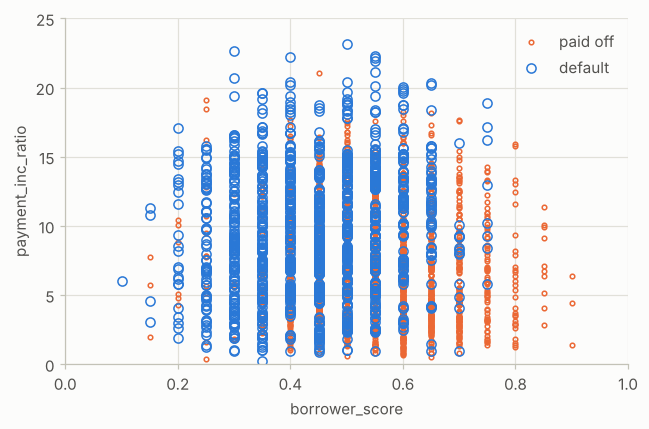

In [21]:
# BOOK CODE (XGBoost): the predicted classes in the plane of the predictors
fig, ax = plt.subplots(figsize=(6, 4))

xgb_df.loc[xgb_df.prediction=='paid off'].plot(
    x='borrower_score', y='payment_inc_ratio', style='.',
    markerfacecolor='none', markeredgecolor='C1', ax=ax)
xgb_df.loc[xgb_df.prediction=='default'].plot(
    x='borrower_score', y='payment_inc_ratio', style='o',
    markerfacecolor='none', markeredgecolor='C0', ax=ax)
ax.legend(['paid off', 'default']);
ax.set_xlim(0, 1)
ax.set_ylim(0, 25)
ax.set_xlabel('borrower_score')
ax.set_ylabel('payment_inc_ratio')

plt.tight_layout()
plt.show()

Regularization. All the loans and the 33 columns are used, with 10,000 loans held out for validation (the split is random and the script has no seed: the cell starts with one, marked `NOT IN THE BOOK`). Two models with 250 trees of depth 6 are fitted, with and without a penalty, and their misclassification rates (the share of loans for which the predicted probability is on the wrong side of 0.5) are printed.

In [22]:
# BOOK CODE (Regularization: Avoiding Overfitting): the models with and without a penalty
np.random.seed(1)  # NOT IN THE BOOK: the validation split is random and the script has no seed

predictors = ['loan_amnt', 'term', 'annual_inc', 'dti',
              'payment_inc_ratio', 'revol_bal', 'revol_util',
              'purpose', 'delinq_2yrs_zero', 'pub_rec_zero',
              'open_acc', 'grade', 'emp_length', 'purpose_',
              'home_', 'emp_len_', 'borrower_score']
outcome = 'outcome'

X = pd.get_dummies(loan_data[predictors], drop_first=True, dtype=int)
y = pd.Series([1 if o == 'default' else 0 for o in loan_data[outcome]])

train_X, valid_X, train_y, valid_y = train_test_split(X, y, test_size=10000)

xgb_default = XGBClassifier(objective='binary:logistic', n_estimators=250, max_depth=6,
                            reg_lambda=0, learning_rate=0.3, subsample=1,
                            eval_metric='error')
xgb_default.fit(train_X, train_y)

xgb_penalty = XGBClassifier(objective='binary:logistic', n_estimators=250, max_depth=6,
                            reg_lambda=1000, learning_rate=0.1, subsample=0.63,
                            eval_metric='error')
print(xgb_penalty.fit(train_X, train_y))

pred_default = xgb_default.predict_proba(train_X)[:, 1]
error_default = abs(train_y - pred_default) > 0.5
print('default (train): ', np.mean(error_default))

pred_default = xgb_default.predict_proba(valid_X)[:, 1]
error_default = abs(valid_y - pred_default) > 0.5
print('default: ', np.mean(error_default))

pred_penalty = xgb_penalty.predict_proba(valid_X)[:, 1]
error_penalty = abs(valid_y - pred_penalty) > 0.5
print('penalty: ', np.mean(error_penalty))

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='error', feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.1, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=6,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=250,
              n_jobs=None, num_parallel_tree=None, ...)
default (train):  0.1055401505291155
default:  0.3611
penalty:  0.3331


The errors of both models as trees are added, on the training and on the validation data. The loop predicts with the first `ntree_limit` trees by restricting the prediction to a range of boosting rounds (`iteration_range`).

   iterations  default train  penalty train  default test  penalty test
0           1       0.345623       0.354507        0.3541        0.3576
1           2       0.330938       0.344208        0.3454        0.3468
2           3       0.325505       0.341209        0.3441        0.3455
3           4       0.319903       0.342991        0.3416        0.3452
4           5       0.318318       0.337446        0.3432        0.3401


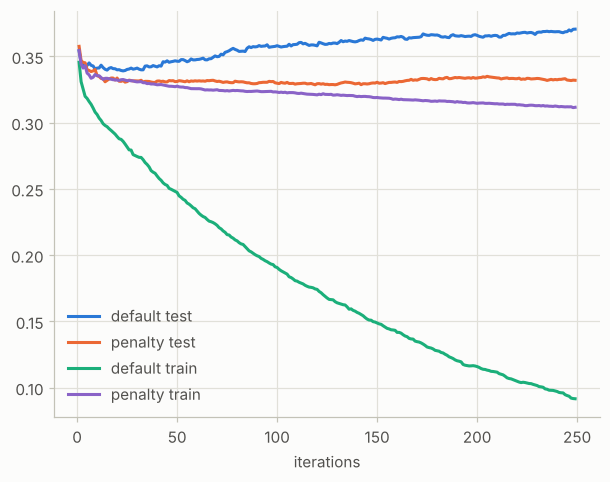

In [23]:
# BOOK CODE (Regularization: Avoiding Overfitting): the errors against the number of trees
results = []
for ntree_limit in range(1, 250):
    iteration_range = [1, ntree_limit + 1]
    train_default = xgb_default.predict_proba(train_X, iteration_range=iteration_range)[:, 1]
    train_penalty = xgb_penalty.predict_proba(train_X, iteration_range=iteration_range)[:, 1]
    pred_default = xgb_default.predict_proba(valid_X, iteration_range=iteration_range)[:, 1]
    pred_penalty = xgb_penalty.predict_proba(valid_X, iteration_range=iteration_range)[:, 1]
    results.append({
        'iterations': ntree_limit,
        'default train': np.mean(abs(train_y - train_default) > 0.5),
        'penalty train': np.mean(abs(train_y - train_penalty) > 0.5),
        'default test': np.mean(abs(valid_y - pred_default) > 0.5),
        'penalty test': np.mean(abs(valid_y - pred_penalty) > 0.5),
    })

results = pd.DataFrame(results)
print(results.head())

ax = results.plot(x='iterations', y='default test')
results.plot(x='iterations', y='penalty test', ax=ax)
results.plot(x='iterations', y='default train', ax=ax)
results.plot(x='iterations', y='penalty train', ax=ax)
plt.show()

Hyperparameters and cross-validation. Every loan is assigned to one of five folds at random (the script has no seed: the cell starts with one, marked `NOT IN THE BOOK`), and the 9 combinations of the learning rate (`eta`) and the maximum depth are evaluated by five-fold cross-validation, 45 fits of 250 trees. The last output is the table of the average errors in per cent.

In [24]:
# BOOK CODE (Hyperparameters and Cross-Validation): the grid of eta and max_depth
np.random.seed(1)  # NOT IN THE BOOK: the assignment of the folds is random and the script has no seed

idx = np.random.choice(range(5), size=len(X), replace=True)
error = []
for eta, max_depth in product([0.1, 0.5, 0.9], [3, 6, 9]):
    xgb = XGBClassifier(objective='binary:logistic', n_estimators=250,
                        max_depth=max_depth, learning_rate=eta,
                        eval_metric='error')
    cv_error = []
    for k in range(5):
        fold_idx = idx == k
        train_X = X.loc[~fold_idx]; train_y = y[~fold_idx]
        valid_X = X.loc[fold_idx]; valid_y = y[fold_idx]

        xgb.fit(train_X, train_y)
        pred = xgb.predict_proba(valid_X)[:, 1]
        cv_error.append(np.mean(abs(valid_y - pred) > 0.5))
    error.append({
        'eta': eta,
        'max_depth': max_depth,
        'avg_error': np.mean(cv_error)
    })
    print(error[-1])
errors = pd.DataFrame(error)
print(errors)

print(errors.pivot_table(index='eta', columns='max_depth', values='avg_error') * 100)

{'eta': 0.1, 'max_depth': 3, 'avg_error': np.float64(0.32763534410706074)}
{'eta': 0.1, 'max_depth': 6, 'avg_error': np.float64(0.33802763403824565)}
{'eta': 0.1, 'max_depth': 9, 'avg_error': np.float64(0.3460295504436688)}
{'eta': 0.5, 'max_depth': 3, 'avg_error': np.float64(0.341132477381365)}
{'eta': 0.5, 'max_depth': 6, 'avg_error': np.float64(0.3698900014913674)}
{'eta': 0.5, 'max_depth': 9, 'avg_error': np.float64(0.37238274838814334)}
{'eta': 0.9, 'max_depth': 3, 'avg_error': np.float64(0.3533284035713775)}
{'eta': 0.9, 'max_depth': 6, 'avg_error': np.float64(0.3858040179919801)}
{'eta': 0.9, 'max_depth': 9, 'avg_error': np.float64(0.38226591098342266)}
   eta  max_depth  avg_error
0  0.1          3   0.327635
1  0.1          6   0.338028
2  0.1          9   0.346030
3  0.5          3   0.341132
4  0.5          6   0.369890
5  0.5          9   0.372383
6  0.9          3   0.353328
7  0.9          6   0.385804
8  0.9          9   0.382266
max_depth          3          6          

**Output analysis.**

* **The first model.** The table has the predicted class of the first five loans and the column `prob_default`: 0.667 (predicted paid off), 0.311 (default), 0.285 (default), 0.754 (paid off) and 0.048 (default). The loans predicted to pay off have values above 0.5 and those predicted to default below it, so this column is in fact the probability of *paid off* (see the notes at the end). The figure shows the predicted classes: the boundary is more fragmented than that of the single tree, with islands of one class inside the region of the other.
* **Overfitting and the penalty.** The model with `reg_lambda=0` has an error of 0.106 on the training loans and 0.361 on the 10,000 validation loans: a gap of 0.26, a clear case of overfitting. The penalized model (`reg_lambda=1000`, learning rate 0.1, subsample 0.63) has a validation error of 0.333, 0.028 lower.
* **The errors against the number of trees.** The table starts with the errors of the first five iterations (for example 0.346 on the training data and 0.354 on the validation data for the default model after one iteration). In the figure the training error of the default model falls steadily to 0.092 for 249 trees. Its validation error has its minimum, 0.339, for 23 trees and then rises to 0.371: after a few dozen trees each new tree fits noise. The penalized model hardly overfits: its training error falls slowly to 0.312 and its validation error has a shallow minimum of 0.329 for 119 trees and stays at about 0.33 from the first dozen trees on. The last point of the curve of the default model (0.371) is above the 0.361 printed above for the same model; the reason is the range `[1, ntree_limit + 1]` of the loop, which leaves out the first round of boosting (see the notes at the end).
* **Cross-validation.** The lowest average error of the 9 combinations is 0.3276 for $\eta = 0.1$ and a depth of 3. The errors in per cent are 32.8, 33.8 and 34.6 for $\eta = 0.1$ and depths 3, 6 and 9; 34.1, 37.0 and 37.2 for $\eta = 0.5$; 35.3, 38.6 and 38.2 for $\eta = 0.9$. The error rises with the learning rate and, except for the last row (depth 9 is a little better than depth 6 for $\eta = 0.9$), with the depth: bigger steps and deeper trees overfit more with 250 trees. The best combination is at the corner of the grid (the smallest $\eta$ and the smallest depth), so the grid is too small to say that it is the optimum: a smaller learning rate with more trees, or shallower trees, could do better.

---
## Chapter summary

**The methods of this chapter are data-driven and predict well, at the price of readability.** **K-nearest neighbors** classifies a record by a vote of the most similar records and needs standardized predictors; **tree models** are readable if-then rules found by recursive partitioning that lowers an impurity measure (Gini impurity or entropy) and has to be stopped or pruned; the **random forest** averages many trees fitted to bootstrap samples with a random subset of predictors at each split, gives an out-of-bag error estimate and variable importance; **boosting** (XGBoost) fits trees in sequence, each correcting the previous ones, and needs regularization and cross-validation of its hyperparameters.

### Key takeaways

1. A KNN model with $K = 20$ and two predictors classifies the first loan of the data as paid off with a probability of default of 0.45; without standardization the revolving balance decides the neighbours (section 1).
2. A tree with two predictors has 6 leaves and classifies 61.1% of the 3,000 training loans correctly; its first question is whether the borrower score is at most 0.575 (section 2).
3. The out-of-bag accuracy of a forest on these two predictors is about 61% for any number of trees from 20 to 505 (section 3).
4. By permutation the borrower score (0.076), the grade (0.042) and the term (0.031) are the most important predictors; by the Gini decrease the numeric variables with many values come out on top, which is a known bias of that measure (section 3).
5. An unpenalized XGBoost model has a training error of 0.106 and a validation error of 0.361; with the penalty and a smaller learning rate the validation error is 0.333 (section 4).
6. Cross-validation over the learning rate and the depth gives the lowest error, 0.3276, for $\eta = 0.1$ and a depth of 3, at the edge of the grid (section 4).

### Book vs. library notes

The official code of the chapter ran in this notebook with the versions printed by the setup cell, with the additions below and no changes to the book code itself. Everything else, in particular what the plots look like and the exact numbers of the random parts, may differ in other versions of the libraries (and `xgboost`, which uses several threads, can give slightly different numbers on another machine).

* **Paths.** The official script finds its data folder with a helper module; here `DATA` comes from the setup cell, which also downloads the files from the official repository if they are missing.
* **Graphviz.** The tree of section 2 is drawn by `plotDecisionTree` of `dmba`, which calls the program `dot` of Graphviz; without it the cell fails. It is present in Google Colab; elsewhere it has to be installed with the package manager of the system.
* **The backend of Matplotlib.** Importing `dmba` prints `no display found. Using non-interactive Agg backend` and selects that backend when no display is found (a server, a background run). Then no figure is shown in a notebook, so the cell after the imports, which is not in the book, runs `%matplotlib inline`.
* **Seeds.** The jitter of the borrower-score plot (`random.gauss`), the forest, the splits and the permutations of the accuracy decrease (`np.random.seed` before the cell, which seeds the unseeded forest, `train_test_split` and `np.random.permutation`), the validation split of the regularization example and the assignment of the cross-validation folds are random and the script has no seed; each of these cells starts with a seeding line marked `# NOT IN THE BOOK`. The forests and trees with `random_state=1` in the script are fixed already, and `XGBClassifier` has its own default seed. With the seeds the numbers are repeatable, but they differ a little from those of the unseeded script (for example the validation error of the default model was 0.352, not 0.361, in one unseeded run).
* **The class order and `borrower_score`.** The script converts `outcome` to a categorical variable with the order *paid off*, *default*, but scikit-learn uses the classes in alphabetical order, `['default' 'paid off']`, so the first column of `predict_proba` is the probability of *default*. The data file already has a column `borrower_score` (a score where a higher value means a safer loan: its mean is 0.535 for the loans paid off and 0.463 for those in default); the KNN cell overwrites it with the probability of default (mean 0.465 for the loans paid off and 0.537 for those in default), which runs in the opposite direction. The later models of this notebook (the forest and XGBoost on all the loans) use the overwritten column, and the models on `loan3000.csv` use the original one. For tree-based models the direction does not matter, but the two columns are not the same variable.
* **`prob_default`.** The XGBoost cell computes `xgb.predict_proba(X)[:, 0]` and calls it `prob_default`; the outcome is coded 1 for default and 0 for paid off, so column 0 is the probability of *paid off* (the loans predicted as paid off have a value above 0.5). The name is wrong, the code itself is as in the script.
* **`iteration_range`.** The loop of the regularization example uses `iteration_range = [1, ntree_limit + 1]`. XGBoost counts the boosting rounds from 0 and the range is half open, so this range leaves out the first round; I checked that `iteration_range=(0, 1)` and `(1, 2)` give different predictions. As a result the curves are those of the rounds 1 to `ntree_limit`, and the last point of the curve of the default model (a validation error of 0.371, with 249 rounds) is above the error of the complete model (0.361, with all 250 rounds). I left the code as in the script.
* **Printed objects.** `print(xgb.fit(X, y))` shows the estimator with many parameters as `None` and `enable_categorical=True`; the parameters that are `None` take the defaults of the installed `xgboost`. With `numpy` 2 the probabilities of the tree and the entries of the cross-validation dictionaries are printed as `np.float64(...)`.
* **The run time.** The notebook takes about eight minutes on a machine with four cores, mostly for the 98 forests of the out-of-bag loop and the 45 XGBoost models of the cross-validation.

---
## References

* Bruce, P., Bruce, A. and Gedeck, P. (2020). *Practical Statistics for Data Scientists: 50+ Essential Concepts Using R and Python*, 2nd edition. O'Reilly Media.
* Official code and data of the book: `gedeck/practical-statistics-for-data-scientists` on GitHub (GNU General Public License v3).
* Breiman, L., Friedman, J. H., Olshen, R. A. and Stone, C. J. (1984). *Classification and Regression Trees*. Wadsworth.
* Breiman, L. (2001). Random forests. *Machine Learning*, 45(1), 5-32.
* Chen, T. and Guestrin, C. (2016). XGBoost: a scalable tree boosting system. *Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining (KDD '16)*, 785-794.
* Cover, T. M. and Hart, P. E. (1967). Nearest neighbor pattern classification. *IEEE Transactions on Information Theory*, 13(1), 21-27.
* Friedman, J. H. (2001). Greedy function approximation: a gradient boosting machine. *The Annals of Statistics*, 29(5), 1189-1232.
* The versions of `NumPy`, `pandas`, `SciPy`, `scikit-learn`, `XGBoost`, `seaborn` and `Matplotlib` are printed by the setup cell.